# 1. Pipeline de Preprocesamiento para la Clasificación de Datos de Expresión Génica

## Introducción

Este proyecto tiene como objetivo desarrollar un pipeline de preprocesamiento y Machine Learning utilizando **Python y Scikit-Learn**, aplicado a un conjunto de datos sintético que combina perfiles de expresión génica con características clínicas y demográficas.

La práctica se centra en construir un flujo de trabajo reproducible que integre la limpieza, transformación y preparación de los datos con el entrenamiento de un modelo de clasificación, evitando la fuga de información (*data leakage*).

## Objetivo del proyecto

Construir un pipeline que permita clasificar las muestras en dos grupos:

* **Sano:** individuos sin enfermedad.
* **Enfermedad:** individuos con Disease A o Disease B.

Para ello, se utilizará `DiseaseStatus` como variable objetivo, agrupando las categorías correspondientes a ambas enfermedades en una única clase.

El modelo inicial será una regresión logística, elegida por su sencillez y utilidad como punto de partida para un problema de clasificación binaria.

## Metodología

El desarrollo se organizará en las siguientes etapas:

1. **Carga y exploración:** inspección de la estructura, los tipos de datos y la distribución de las variables.
2. **Auditoría de calidad:** identificación de valores faltantes, registros duplicados y posibles valores atípicos (*outliers*).
3. **Preparación de los datos:** selección de variables predictoras y definición de la variable objetivo.
4. **División del dataset:** separación en conjuntos de entrenamiento y prueba antes de ajustar los transformadores.
5. **Preprocesamiento:** imputación de valores faltantes, escalado de variables numéricas y codificación de variables categóricas mediante `ColumnTransformer`.
6. **Entrenamiento y evaluación:** integración del preprocesamiento y el modelo en un único `Pipeline`, con evaluación mediante métricas de clasificación.
7. **Persistencia:** exportación del pipeline entrenado mediante `joblib` para su reutilización con nuevos datos.

## Consideraciones metodológicas

El preprocesamiento se ajustará exclusivamente con los datos de entrenamiento, para evitar que la información del conjunto de prueba influya en las transformaciones.

Se analizará el desbalance de clases y se priorizarán métricas que permitan evaluar el desempeño sobre la clase minoritaria, además de la exactitud global (*accuracy*).

El dataset es sintético y tiene fines educativos. Por lo tanto, los resultados no constituyen evidencia clínica ni permiten extraer conclusiones sobre enfermedades o biomarcadores reales.

## Herramientas

* Python
* Pandas y NumPy
* Matplotlib y Seaborn
* Scikit-Learn
* Joblib
* Jupyter Notebook

## 2. Carga y exploración inicial de los datos

En esta etapa se carga el dataset y se realiza una primera inspección de su estructura.

El objetivo es conocer las dimensiones del conjunto de datos, identificar las variables disponibles y verificar sus tipos de datos antes de iniciar el preprocesamiento.

Esta exploración permitirá detectar posibles inconsistencias y definir las decisiones de limpieza necesarias para construir el pipeline.

Se analizarán los siguientes aspectos:

* Cantidad de registros y variables.
* Nombres y tipos de datos de las columnas.
* Primeras observaciones del dataset.
* Valores faltantes y registros duplicados.
* Distribución de la variable objetivo `DiseaseStatus`.

Los resultados de esta etapa servirán como base para las decisiones metodológicas de las siguientes secciones.


In [2]:
# Importación de librerías para la exploración y el análisis de datos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuración para visualizar todas las columnas del dataset
pd.set_option("display.max_columns", None)

# Ruta al archivo CSV
ruta_datos = Path("C:/Users/luisi/Desktop/Bioinformatica/Data Science/Data science II/gene-expression-preprocessing-pipeline/data/Gene Expression Analysis and Disease Relationship.csv")

# Carga del dataset
df = pd.read_csv(ruta_datos)

# Visualización de las primeras cinco filas
display(df.head())

,PatientID,Age,Gender,Gene_X_Expression,Gene_Y_Expression,SmokingStatus,DiseaseStatus,TreatmentResponse
0,1,45,0,5.78,3.21,1,1,1
1,2,62,1,7.12,5.89,2,2,0
2,3,38,0,3.15,1.98,0,0,2
3,4,55,1,6.54,4.76,1,1,1
4,5,71,0,8.01,6.55,2,2,0


In [3]:
# Dimensiones del dataset
print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

# Información general sobre las variables
df.info()

Cantidad de registros: 1000
Cantidad de columnas: 8
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PatientID          1000 non-null   int64  
 1   Age                1000 non-null   int64  
 2   Gender             1000 non-null   int64  
 3   Gene_X_Expression  1000 non-null   float64
 4   Gene_Y_Expression  1000 non-null   float64
 5   SmokingStatus      1000 non-null   int64  
 6   DiseaseStatus      1000 non-null   int64  
 7   TreatmentResponse  1000 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


## 3. Auditoría de calidad de los datos

En esta etapa se evalúa la calidad inicial del dataset mediante la identificación de valores faltantes, registros duplicados y posibles valores atípicos.

Esta revisión permite detectar problemas que podrían afectar el entrenamiento del modelo y definir las estrategias de preprocesamiento adecuadas. Los valores extremos no se eliminarán automáticamente: primero se analizará si son errores o valores plausibles.


In [4]:
# Cantidad de valores faltantes por columna
print("Valores faltantes por columna:")
display(df.isnull().sum())

# Cantidad de registros duplicados
print("Cantidad de filas duplicadas:", df.duplicated().sum())

# Cantidad de identificadores únicos, si existe la columna
if "PatientID" in df.columns:
    print("Cantidad de pacientes únicos:", df["PatientID"].nunique())

Valores faltantes por columna:


PatientID            0
Age                  0
Gender               0
Gene_X_Expression    0
Gene_Y_Expression    0
SmokingStatus        0
DiseaseStatus        0
TreatmentResponse    0
dtype: int64

Cantidad de filas duplicadas: 0
Cantidad de pacientes únicos: 1000


## 4. Análisis exploratorio de las variables

En esta etapa se examinan las distribuciones de las variables numéricas y categóricas, con especial atención a la variable objetivo `DiseaseStatus`.

El análisis permite identificar posibles desequilibrios entre clases, verificar los valores codificados de las categorías y reconocer valores extremos que requieran una revisión adicional antes del entrenamiento.

Como el dataset es sintético, los patrones observados se interpretarán únicamente con fines educativos y metodológicos, sin extraer conclusiones clínicas.


In [5]:
# Revisar los valores posibles de las variables categóricas
for columna in ["Gender", "SmokingStatus", "DiseaseStatus", "TreatmentResponse"]:
    print(f"\nDistribución de {columna}:")
    display(df[columna].value_counts().sort_index())

# Estadísticas descriptivas de las variables numéricas
print("\nEstadísticas descriptivas:")
display(
    df[["Age", "Gene_X_Expression", "Gene_Y_Expression"]]
    .describe()
    .round(2)
    .T
)



Distribución de Gender:


Gender
0    500
1    500
Name: count, dtype: int64


Distribución de SmokingStatus:


SmokingStatus
0    962
1     18
2     20
Name: count, dtype: int64


Distribución de DiseaseStatus:


DiseaseStatus
0    962
1     18
2     20
Name: count, dtype: int64


Distribución de TreatmentResponse:


TreatmentResponse
0     20
1     18
2    962
Name: count, dtype: int64


Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
Age,1000.0,49.63,17.61,20.00,34.00,49.00,65.00,80.00
Gene_X_Expression,1000.0,3.92,2.00,0.51,2.20,3.88,5.61,9.01
Gene_Y_Expression,1000.0,3.63,1.95,0.30,1.95,3.58,5.33,7.55


## 5. Preparación de las variables predictoras y la variable objetivo

Para transformar el problema en una clasificación binaria, se agrupan las categorías de enfermedad A y enfermedad B en una única clase positiva.

La variable objetivo se define de la siguiente manera:

* `0`: paciente sano.
* `1`: paciente con enfermedad.

Se excluyen `PatientID`, por ser un identificador sin significado predictivo directo, y `TreatmentResponse`, porque podría contener información que no estaría disponible al momento de realizar una predicción.

Las variables `Age`, `Gene_X_Expression` y `Gene_Y_Expression` se consideran numéricas. `Gender` y `SmokingStatus` se tratarán como categóricas, aunque estén codificadas mediante números.


In [6]:
# Crear una copia de trabajo para conservar el dataset original
df_modelo = df.copy()

# Agrupar las categorías de DiseaseStatus:
# 0 = sano; 1 y 2 = con enfermedad
df_modelo["DiseaseStatus"] = (
    df_modelo["DiseaseStatus"].map({0: 0, 1: 1, 2: 1})
)

# Definir las variables predictoras y la variable objetivo
columnas_numericas = [
    "Age",
    "Gene_X_Expression",
    "Gene_Y_Expression"
]

columnas_categoricas = [
    "Gender",
    "SmokingStatus"
]

X = df_modelo[columnas_numericas + columnas_categoricas]
y = df_modelo["DiseaseStatus"]

# Verificar las dimensiones y la distribución de la variable objetivo
print("Dimensiones de X:", X.shape)
print("\nDistribución de la variable objetivo:")
display(y.value_counts().sort_index())

print("\nProporción de cada clase:")
display((y.value_counts(normalize=True).sort_index() * 100).round(2))

Dimensiones de X: (1000, 5)

Distribución de la variable objetivo:


DiseaseStatus
0    962
1     38
Name: count, dtype: int64


Proporción de cada clase:


DiseaseStatus
0    96.2
1     3.8
Name: proportion, dtype: float64

## 6. División de los datos en entrenamiento y prueba

Se separan los datos en un conjunto de entrenamiento (80 %) y otro de prueba (20 %). Se utiliza `stratify=y` para conservar aproximadamente la proporción original de pacientes sanos y pacientes con enfermedad en ambos conjuntos.

Esta separación se realiza antes de ajustar cualquier transformación, evitando que la información del conjunto de prueba intervenga en el aprendizaje del preprocesamiento.

Debido al desbalance de clases, se espera que el conjunto de prueba contenga pocos casos positivos. Por ello, sus métricas se interpretarán con cautela.


In [7]:
# División de los datos en entrenamiento y prueba
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verificar las dimensiones de cada conjunto
print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)

# Comparar la distribución de clases en ambos conjuntos
print("\nDistribución en entrenamiento:")
display(y_train.value_counts().sort_index())

print("\nProporción en entrenamiento (%):")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nDistribución en prueba:")
display(y_test.value_counts().sort_index())

print("\nProporción en prueba (%):")
display((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

Dimensiones de X_train: (800, 5)
Dimensiones de X_test: (200, 5)

Distribución en entrenamiento:


DiseaseStatus
0    770
1     30
Name: count, dtype: int64


Proporción en entrenamiento (%):


DiseaseStatus
0    96.25
1     3.75
Name: proportion, dtype: float64


Distribución en prueba:


DiseaseStatus
0    192
1      8
Name: count, dtype: int64


Proporción en prueba (%):


DiseaseStatus
0    96.0
1     4.0
Name: proportion, dtype: float64

## 7. Construcción del pipeline de preprocesamiento y clasificación

Se construye un pipeline que integra las transformaciones de datos y el estimador en un único flujo reproducible.

Para las variables numéricas se utiliza imputación por mediana y estandarización. Para las variables categóricas se aplica imputación por la categoría más frecuente y codificación One-Hot, configurada para ignorar categorías desconocidas.

Un `ColumnTransformer` permite aplicar cada transformación a las columnas correspondientes, mientras que `Pipeline` encadena el preprocesamiento y la regresión logística. Se utiliza `class_weight="balanced"` para asignar mayor peso a la clase minoritaria durante el entrenamiento.

Todas las transformaciones se ajustan exclusivamente con los datos de entrenamiento, reduciendo el riesgo de fuga de información.


In [13]:
# Importar herramientas de preprocesamiento y modelado
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Pipeline para variables numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(handle_unknown="ignore"))
])

# Aplicar las transformaciones según el tipo de variable
preprocesador = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico, columnas_numericas),
    ("categoricas", pipeline_categorico, columnas_categoricas)
])

# Pipeline completo: preprocesamiento + modelo
pipeline_modelo = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print("Pipeline creado correctamente.")

Pipeline creado correctamente.


## 8. Entrenamiento del modelo

Se ajusta el pipeline completo utilizando exclusivamente el conjunto de entrenamiento. Durante este proceso, los imputadores, el escalador, el codificador y la regresión logística aprenden a partir de esos datos.

El conjunto de prueba permanece separado para evaluar el rendimiento del modelo sobre observaciones no utilizadas durante el entrenamiento.


In [14]:
# Entrenar el pipeline completo
pipeline_modelo.fit(X_train, y_train)

print("Entrenamiento completado correctamente.")

Entrenamiento completado correctamente.


## 9. Evaluación del modelo

Se evalúa el rendimiento sobre el conjunto de prueba mediante la matriz de confusión, el reporte de clasificación, la balanced accuracy y el área bajo la curva ROC (ROC-AUC).

También se analiza la curva Precision-Recall, especialmente relevante debido al fuerte desequilibrio entre las clases.

Las métricas se interpretan teniendo en cuenta que el conjunto de prueba contiene solamente ocho casos positivos, por lo que los resultados pueden variar considerablemente ante pequeños cambios en las predicciones.


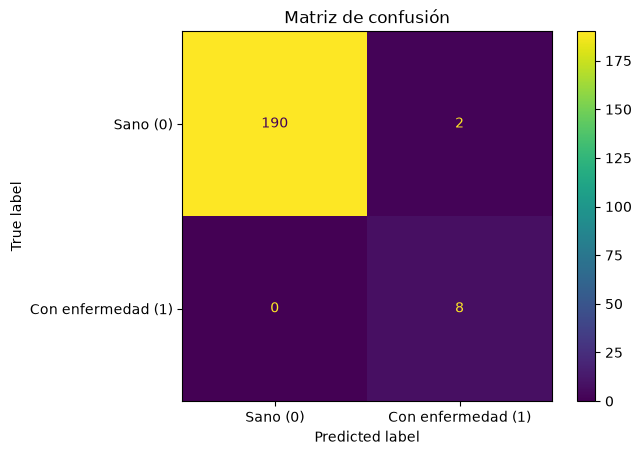

Reporte de clasificación:
                precision    recall  f1-score   support

          Sano       1.00      0.99      0.99       192
Con enfermedad       0.80      1.00      0.89         8

      accuracy                           0.99       200
     macro avg       0.90      0.99      0.94       200
  weighted avg       0.99      0.99      0.99       200

Balanced accuracy: 0.995
ROC-AUC: 1.0


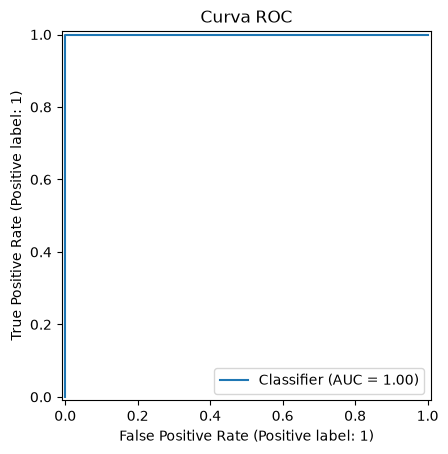

Average Precision: 1.0


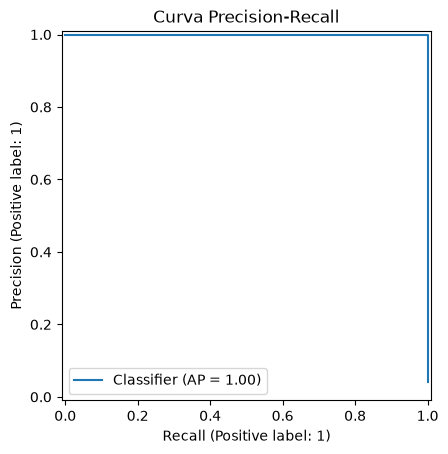

In [15]:
# Importar métricas y herramientas de visualización
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_auc_score,
    RocCurveDisplay,
    precision_recall_curve,
    average_precision_score,
    PrecisionRecallDisplay
)

# Generar predicciones y probabilidades para la clase positiva
y_pred = pipeline_modelo.predict(X_test)
y_prob = pipeline_modelo.predict_proba(X_test)[:, 1]

# Mostrar matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sano (0)", "Con enfermedad (1)"]
)
disp.plot()
plt.title("Matriz de confusión")
plt.show()

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Sano", "Con enfermedad"],
    zero_division=0
))

# Balanced accuracy
print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_test, y_pred), 3)
)

# Curva ROC y ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", round(roc_auc, 3))

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("Curva ROC")
plt.show()

# Curva Precision-Recall y Average Precision
average_precision = average_precision_score(y_test, y_prob)
print("Average Precision:", round(average_precision, 3))

PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Curva Precision-Recall")
plt.show()

## 10. Diagnóstico de posibles relaciones artificiales y fuga de información

Ante un rendimiento perfecto, se revisan las relaciones entre las variables predictoras y la variable objetivo para identificar posibles asociaciones deterministas o artefactos del dataset sintético.

Este análisis permite comprobar si el resultado refleja un patrón genuino presente en los datos o si podría explicarse por variables que codifican indirectamente la respuesta. No se eliminarán variables únicamente por observar una asociación: se analizarán sus frecuencias y su justificación metodológica.


In [11]:
# Relación entre tabaquismo y estado de enfermedad
print("Tabla cruzada: SmokingStatus vs DiseaseStatus")
display(pd.crosstab(
    df_modelo["SmokingStatus"],
    df_modelo["DiseaseStatus"],
    margins=True
))

print("\nProporciones de enfermedad dentro de cada categoría de tabaquismo:")
display(pd.crosstab(
    df_modelo["SmokingStatus"],
    df_modelo["DiseaseStatus"],
    normalize="index"
).round(3))

# Relación entre género y estado de enfermedad
print("\nTabla cruzada: Gender vs DiseaseStatus")
display(pd.crosstab(
    df_modelo["Gender"],
    df_modelo["DiseaseStatus"],
    normalize="index"
).round(3))

# Comparar las variables numéricas según el estado de enfermedad
print("\nEstadísticas por estado de enfermedad:")
display(
    df_modelo.groupby("DiseaseStatus")[
        ["Age", "Gene_X_Expression", "Gene_Y_Expression"]
    ].agg(["mean", "median", "min", "max"]).round(2)
)

Tabla cruzada: SmokingStatus vs DiseaseStatus


DiseaseStatus,0,1,All
SmokingStatus,,,
0,962,0,962
1,0,18,18
2,0,20,20
All,962,38,1000



Proporciones de enfermedad dentro de cada categoría de tabaquismo:


DiseaseStatus,0,1
SmokingStatus,,
0,1.0,0.0
1,0.0,1.0
2,0.0,1.0



Tabla cruzada: Gender vs DiseaseStatus


DiseaseStatus,0,1
Gender,,
0,0.952,0.048
1,0.972,0.028



Estadísticas por estado de enfermedad:


Age                Gene_X_Expression                     \
                mean median min max              mean median   min   max   
DiseaseStatus                                                              
0              49.14   48.0  20  80              3.79   3.74  0.51  7.23   
1              62.16   62.0  45  80              7.21   7.01  5.22  9.01   

              Gene_Y_Expression                     
                           mean median   min   max  
DiseaseStatus                                       
0                          3.55   3.46  0.30  7.02  
1                          5.60   5.72  3.21  7.55

## 11. Revisión de predictores y control de asociaciones artificiales

Durante la auditoría se identificó una asociación determinista entre `SmokingStatus` y `DiseaseStatus`: todas las observaciones de una categoría corresponden a pacientes sanos y las restantes a pacientes con enfermedad.

Esta relación permite recuperar la variable objetivo directamente y produce una evaluación artificialmente perfecta. Para evitar que domine el modelo, se excluye `SmokingStatus` de los predictores en esta versión del experimento.

Esta decisión responde a las características particulares del dataset sintético y no implica que la variable carezca de relevancia clínica en datos reales. Los resultados posteriores se compararán con los obtenidos en la primera versión.


In [12]:
# Redefinir los predictores sin SmokingStatus
columnas_numericas = [
    "Age",
    "Gene_X_Expression",
    "Gene_Y_Expression"
]

columnas_categoricas = [
    "Gender"
]

X = df_modelo[columnas_numericas + columnas_categoricas]
y = df_modelo["DiseaseStatus"]

# Repetir la división estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensiones de entrenamiento:", X_train.shape)
print("Distribución en prueba:")
display(y_test.value_counts().sort_index())

Dimensiones de entrenamiento: (800, 4)
Distribución en prueba:


DiseaseStatus
0    192
1      8
Name: count, dtype: int64

## 12. Persistencia del pipeline entrenado

Se guarda el pipeline completo mediante `joblib`, incluyendo las transformaciones de preprocesamiento y el modelo entrenado.

De esta forma, el objeto puede cargarse posteriormente para realizar predicciones sobre nuevos datos sin volver a ajustar los transformadores. Se conserva el flujo completo para garantizar que las nuevas observaciones reciban el mismo tratamiento aplicado durante el entrenamiento.


In [16]:
# Importar las herramientas para guardar el pipeline
import joblib
from pathlib import Path

# Crear la carpeta de modelos si no existe
carpeta_modelos = Path("../models")
carpeta_modelos.mkdir(parents=True, exist_ok=True)

# Guardar el pipeline completo entrenado
ruta_modelo = carpeta_modelos / "pipeline_clasificacion.joblib"
joblib.dump(pipeline_modelo, ruta_modelo)

print(f"Pipeline guardado en: {ruta_modelo}")

Pipeline guardado en: ..\models\pipeline_clasificacion.joblib


In [17]:
# Cargar el pipeline guardado
pipeline_cargado = joblib.load(ruta_modelo)

# Realizar predicciones con el pipeline cargado
predicciones_cargadas = pipeline_cargado.predict(X_test)

# Comprobar que las predicciones coinciden
import numpy as np

print(
    "¿Las predicciones coinciden?",
    np.array_equal(y_pred, predicciones_cargadas)
)

¿Las predicciones coinciden? True
